In [1]:
import copy
from pathlib import Path
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import ep08_plots as viz

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.deterministic = True  # Same number for every run
torch.backends.cudnn.benchmark = False
print(torch.__version__)

2.13.0+cu130


In [5]:
train_set = datasets.FashionMNIST("data", train = True, download = True)
test_set = datasets.FashionMNIST("data", train = True, download = True)
classes = train_set.classes
X = train_set.data.float().unsqueeze(1) / 255   # 1 channel -> grey
y = train_set.targets
X_train, y_train = X[:50000], y[:50000]
X_val, y_val = X[50000:], y[50000:]
X_test = test_set.data.float().unsqueeze(1) / 255
y_test = test_set.targets
print(X_train.shape, X_val.shape, X_test.shape)

100%|██████████| 26.4M/26.4M [00:15<00:00, 1.73MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 206kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.61MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 5.13MB/s]


torch.Size([50000, 1, 28, 28]) torch.Size([10000, 1, 28, 28]) torch.Size([60000, 1, 28, 28])


## Grading

In [6]:
def picks(model, X):
    out = []
    with torch.no_grad():
        for i in range(0, len(X), 1000):     # 1000 photos at a time
            scores = model(X[i:i+1000].to(device))
            out.append(scores.argmax(dim = 1).cpu())
    return torch.cat(out)

def accuracy(model, X, y):
    return round((picks(model, X) == y).float().mean().item(), 3)

def sure(model, X, shelf):
    with torch.no_grad():
        chances = torch.softmax(model(X.to(device)), dim = 1)
    return chances[:, shelf].cpu()

def score(model, X, shelf):
    with torch.no_grad():
        return model(X.to(device))[:, shelf].cpu()

Episode 7:  0.915 | Episode 8's CNN:  0.934


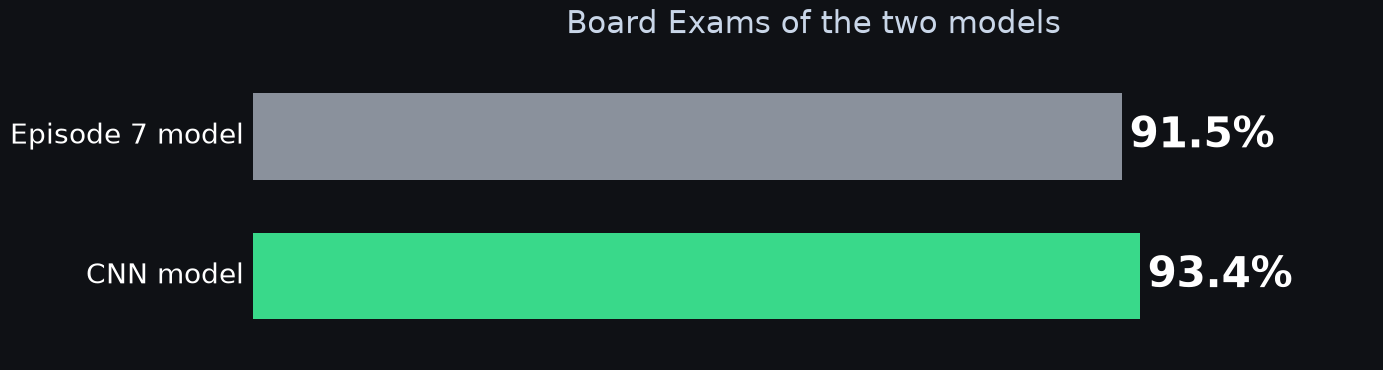

In [7]:
def new_shop_model():
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 128), nn.ReLU(),
        nn.Linear(128, 64), nn.ReLU(),
        nn.Linear(64, 10),
    )

def new_cnn():
    return nn.Sequential(
        nn.Conv2d(1,16,3,padding = 1), nn.ReLU(),  # 16 filters
        nn.MaxPool2d(2),                           # 28 -> 14
        nn.Conv2d(16, 32, 3, padding = 1), nn.ReLU(),  # 16 -> 32 channels
        nn.MaxPool2d(2),                               # 14 -> 7
        nn.Flatten(),                        # [50000, 32, 7, 7] ->  [32*7*7]
        nn.Linear(32*7*7, 10),
    )

shop = new_shop_model().to(device)
shop.load_state_dict(torch.load("shop_model.pt"))
cnn = new_cnn().to(device)
cnn.load_state_dict(torch.load("cnn_model.pt"))
old = accuracy(shop, X_test, y_test)
new = accuracy(cnn, X_test, y_test)
print("Episode 7: ", old, "| Episode 8's CNN: ", new)
viz.reveal_board([("Episode 7 model", old, viz.GREY),
                 ("CNN model", new, viz.NEON)], "Board Exams of the two models")

## Padding

In [8]:
boot = X_val[0:1]
no_border = nn.Conv2d(1,1,3, padding = 0)
border = nn.Conv2d(1,1,3, padding= 1)
print("Padding = 0", tuple(no_border(boot).shape))
print("Padding = 1", tuple(border(boot).shape))

Padding = 0 (1, 1, 26, 26)
Padding = 1 (1, 1, 28, 28)


## Where does CNN look at ?


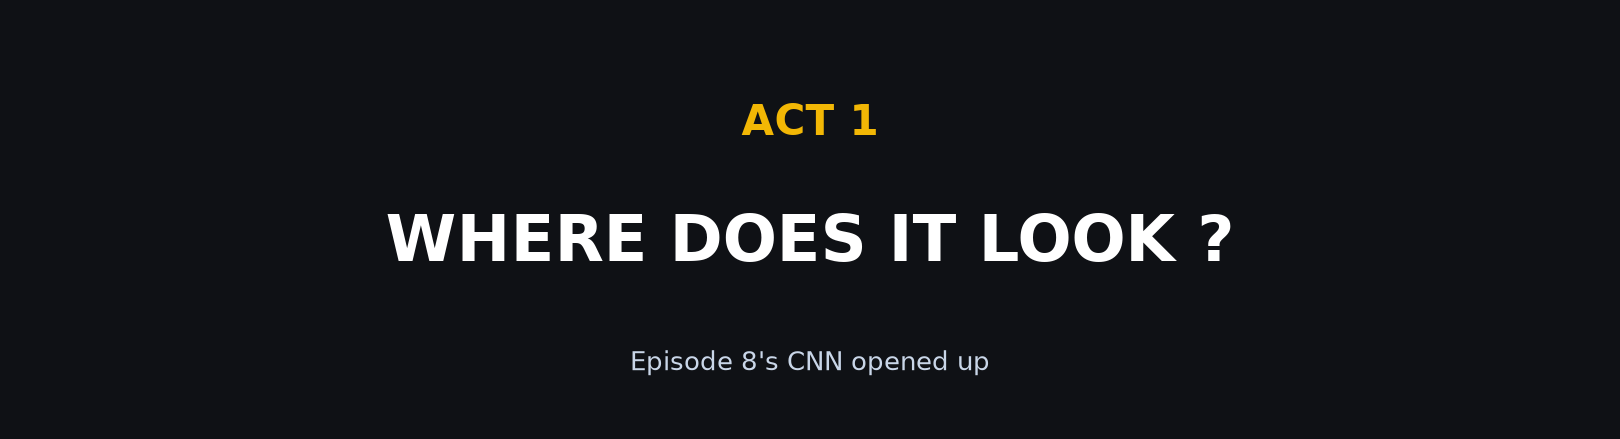

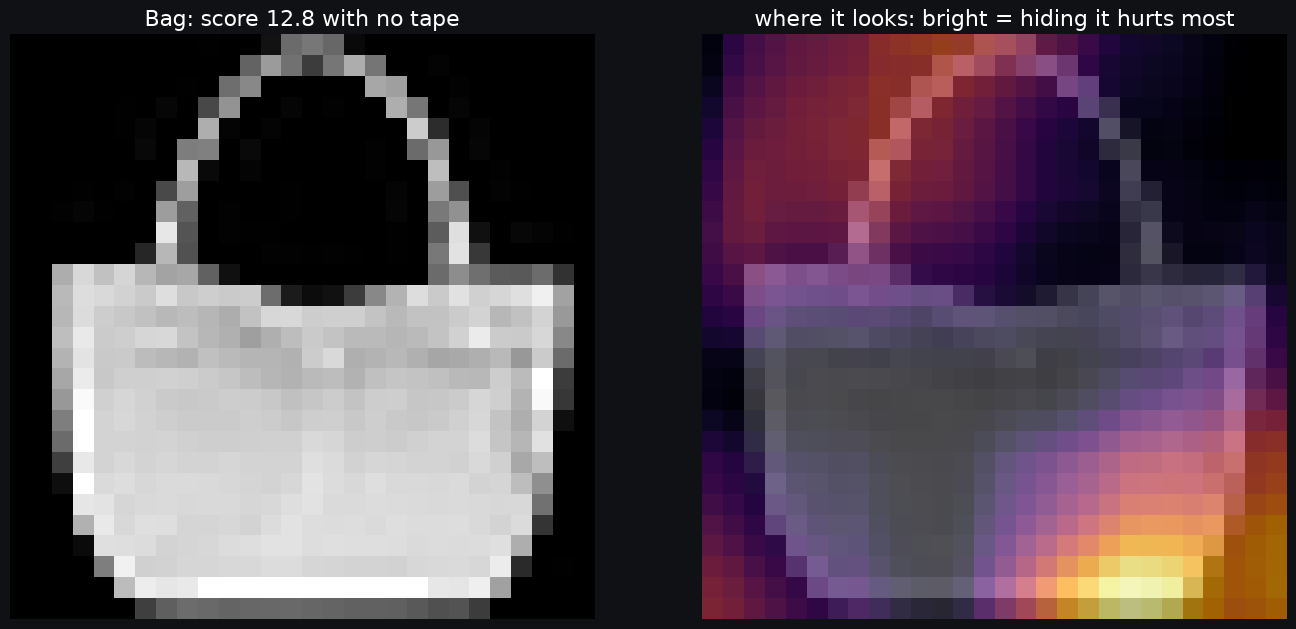

In [12]:
viz.act(1, "Where does it look ?",
        "Episode 8's CNN opened up")

i = 100

photo, shelf = X_test[i:i+1], int(y_test[i])
taped = []
for r in range(21):
    for c in range(21):
        hidden = photo.clone()
        hidden[:,:,r:r + 8, c:c+8] = 0      # this is a 8*8 black tape
        taped.append(hidden)

scores = score(cnn, torch.cat(taped), shelf).reshape(21,21)
base = score(cnn, photo, shelf).item()      # The score with no tape
viz.show_where_it_looks(photo, scores, shelf, classes, base)

Right answers:  56070 | change with one tape:  14123


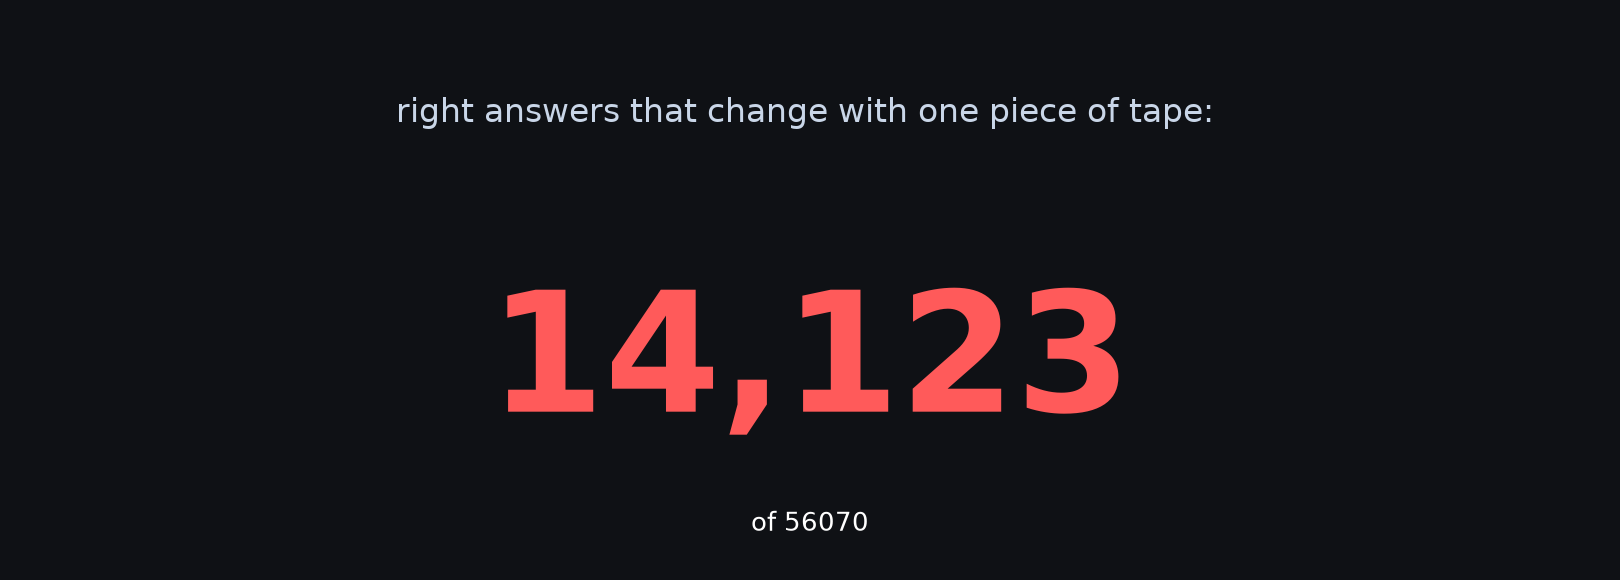

In [15]:
right = picks(cnn, X_test) == y_test
flips = torch.zeros(len(X_test), dtype = torch.bool)

for i in range(0, 21, 2):
    for c in range(0, 21, 2):
        hidden = X_test.clone()
        hidden[:,:, r:r + 8, c:c+8] = 0  # tape on every photo
        flips |= picks(cnn, hidden) != y_test
n_right, n_flip = int(right.sum()), int((right & flips).sum())
print("Right answers: ", n_right, "| change with one tape: ", n_flip)
viz.reveal("right answers that change with one piece of tape: ", n_flip,
           percent = False, colour = viz.HOT,
           note = f"of {n_right}")

## How does a perfect picture looks like for our CNN model


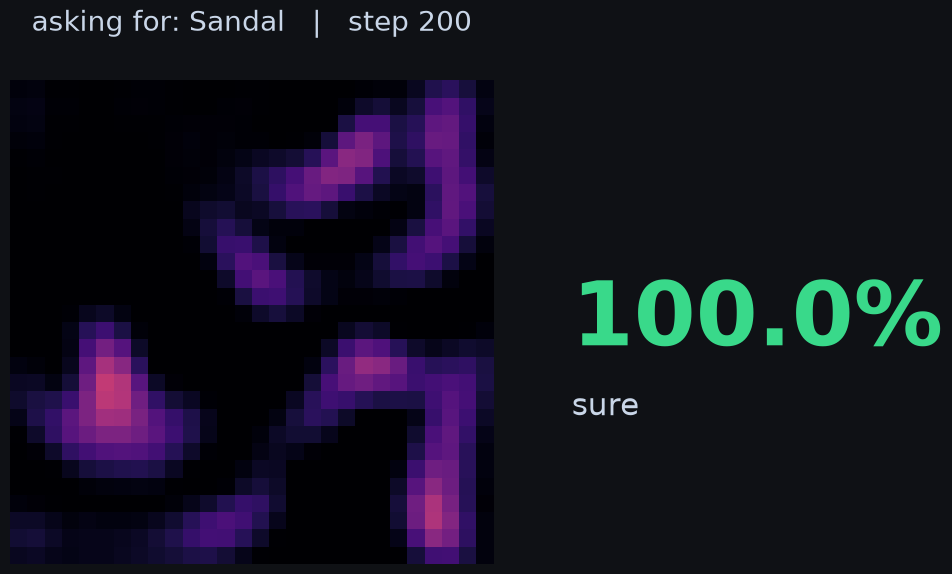

In [16]:
cnn.requires_grad_(False)           # Freeze the model
shelf = 5
torch.manual_seed(42)
photo = (torch.rand(1,1,28,28) * 0.1).to(device)
photo.requires_grad_(True)           # The photo will learn
optimizer = torch.optim.Adam([photo], lr = 0.05)
blur = nn.AvgPool2d(3, stride = 1, padding = 1)
screen = None
for step in range(201):
    dx, dy = torch.randint(-1, 2, (2,)).tolist()   # wiggle the photo
    d_score = cnn(torch.roll(photo, (dx, dy), (2,3)))[0, shelf]
    loss = -d_score + 0.05 *(photo ** 2).sum()   # High score, ink will be faint
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    with torch.no_grad():
        if step % 4 == 0:
            photo.copy_(blur(photo))       # a little blur
        photo.clamp_(0,1)
    if step % 10 == 0:
        p = sure(cnn, photo.detach(), shelf).item()
        screen = viz.watch(photo, step, p, classes[shelf], handle = screen)
                  


## Research labs

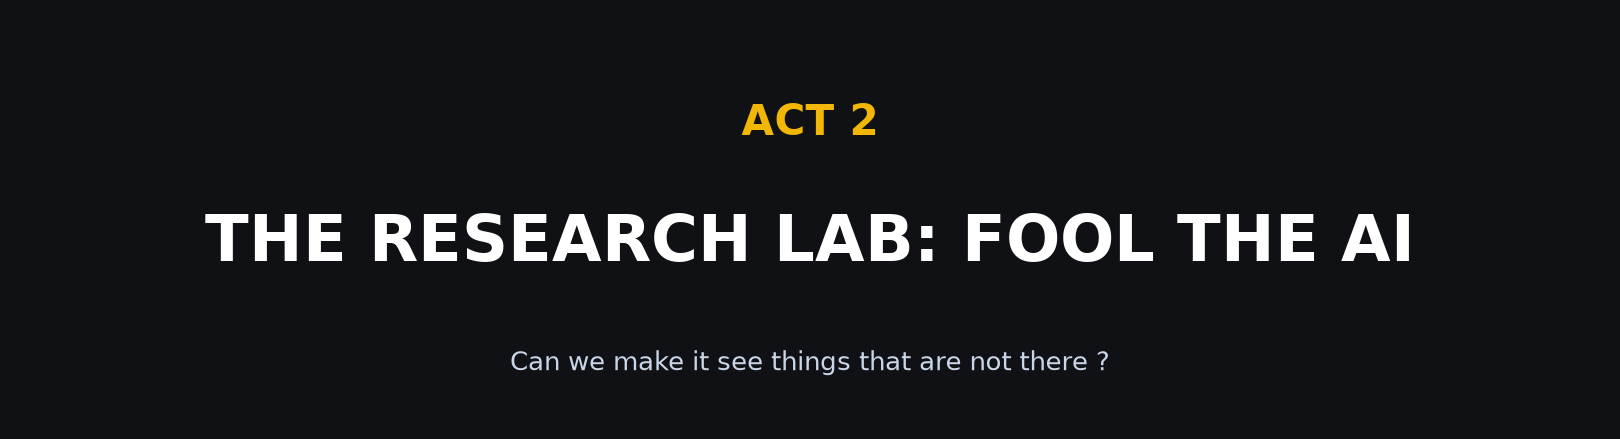

[20, 0, 0, 1, 0, 0, 8399, 0, 1580, 0]
average sureness:  0.851


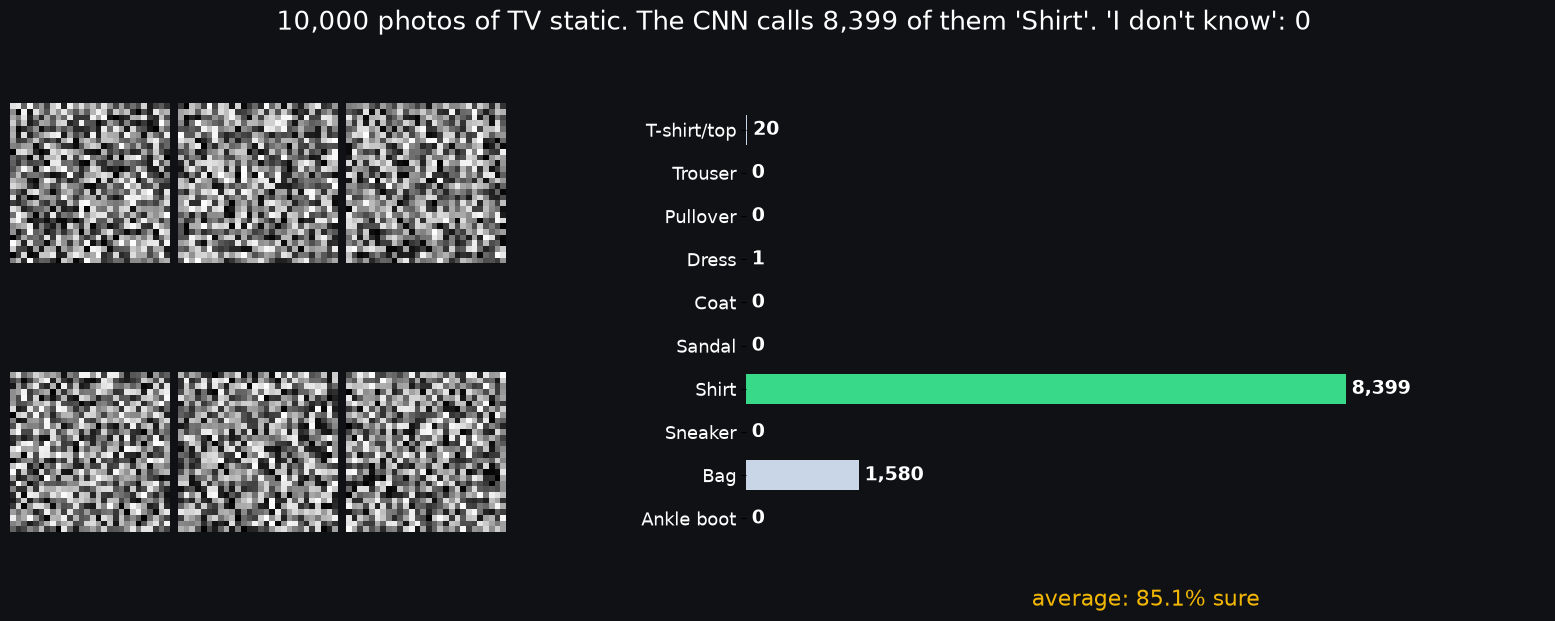

In [17]:
# What if we introduce noise photo to the model 
viz.act(2, "The research lab: Fool the AI",
        "Can we make it see things that are not there ?")
torch.manual_seed(42)
static = torch.rand(10000, 1, 28, 28)    # 10,000 static images
with torch.no_grad():
    chances = torch.softmax(cnn(static.to(device)), dim = 1).cpu()
called = chances.argmax(dim = 1)
print(torch.bincount(called, minlength = 10).tolist())
sureness = chances.max(dim = 1).values   # how sure per photo
print("average sureness: ", round(sureness.mean().item(), 3))
viz.show_static(static, called, sureness, classes)


## Nudge the static towards a particular class

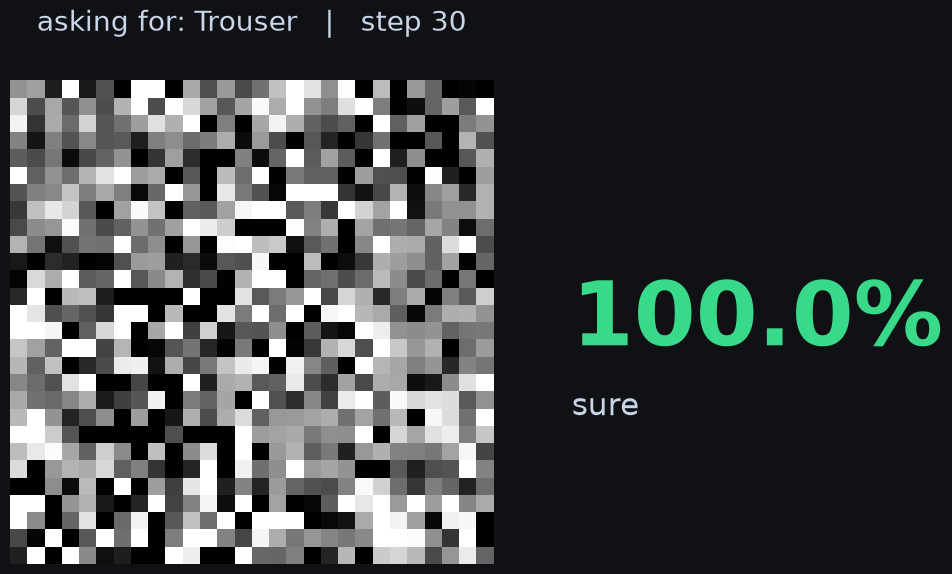

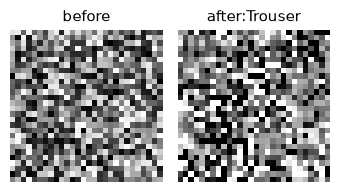

In [18]:
def nudge(start, shelf, steps = 30, show = False):
    photo = start.clone().to(device).requires_grad_(True)
    optimizer = torch.optim.Adam([photo], lr = 0.05)
    screen = None
    for step in range(1, steps + 1):
        loss = -torch.log_softmax(cnn(photo), dim = 1)[0, shelf]
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            photo.clamp_(0,1)
        if show:
            p = sure(cnn, photo.detach(), shelf).item()
            screen = viz.watch(photo, step, p, classes[shelf],
                               style = 'static', handle = screen)
    return photo.detach().cpu()

shelf = 1
after = nudge(static[:1], shelf, show = True)
viz.show_photos(torch.cat([static[:1], after]), cmap = 'gray',
                titles = ['before', 'after:' + classes[shelf]])

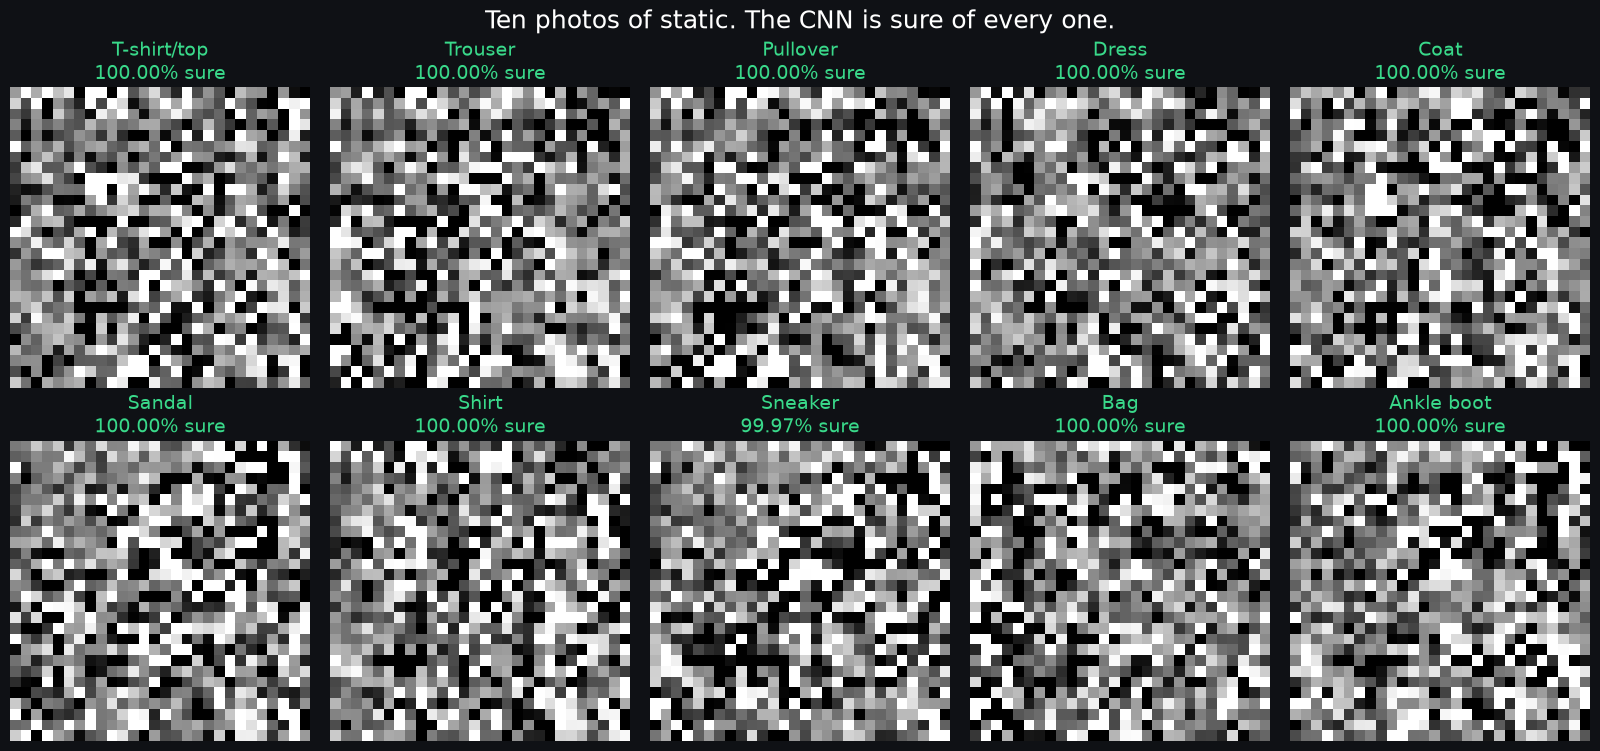

In [19]:
fooled = [nudge(static[:1], k) for k in range(10)]
sure_of = [sure(cnn, fooled[k], k).item() for k in range(10)]
viz.show_fooled(fooled, sure_of, classes)